In [1]:
import mlflow
from pathlib import Path

ROOT = Path("..").resolve()   # racine du projet (chemin absolu)

# Où MLflow écrit : la base de données à la racine du projet
mlflow.set_tracking_uri(f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}")

# Créer le "classeur" une seule fois, avec ses pièces jointes dans mlruns/
EXPERIMENT = "credit_scoring"
if mlflow.get_experiment_by_name(EXPERIMENT) is None:
    mlflow.create_experiment(EXPERIMENT, artifact_location=(ROOT / "mlruns").as_uri())
mlflow.set_experiment(EXPERIMENT)

# Une "fiche" de test
with mlflow.start_run(run_name="test_installation"):
    mlflow.set_tag("type", "test")
    mlflow.log_param("parametre_exemple", 42)
    mlflow.log_metric("metrique_exemple", 0.75)

print("Run enregistré dans", ROOT / "mlflow.db")

c:\Users\A491274\Documents\pret-a-depenser\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Run enregistré dans C:\Users\A491274\Documents\pret-a-depenser\mlflow.db


In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

df = pd.read_parquet(ROOT / "data" / "processed" / "train_final.parquet")
X = df.drop(columns=["SK_ID_CURR", "TARGET"])
y = df["TARGET"].astype(int)
del df

# 20 % sous clé jusqu'à la fin (examen final)
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# Échantillon de 50 000 clients pour comparer les modèles rapidement
X_ech, _, y_ech, _ = train_test_split(
    X_train, y_train, train_size=50_000, stratify=y_train, random_state=42)

print(f"Train : {X_train.shape} | Hold-out : {X_holdout.shape} | Échantillon : {X_ech.shape}")
print(f"% défaut — train {y_train.mean():.2%} | hold-out {y_holdout.mean():.2%} | échantillon {y_ech.mean():.2%}")

Train : (246005, 797) | Hold-out : (61502, 797) | Échantillon : (50000, 797)
% défaut — train 8.07% | hold-out 8.07% | échantillon 8.07%


In [3]:
from sklearn.metrics import confusion_matrix

COUT_FN, COUT_FP = 10, 1

def cout_metier(y_true, y_pred):
    """Coût moyen par client : 10 par mauvais client accepté, 1 par bon client refusé."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return (COUT_FN * fn + COUT_FP * fp) / len(y_true)

def meilleur_seuil(y_true, y_proba, seuils=np.arange(0.01, 1.0, 0.01)):
    """Teste tous les seuils, renvoie celui qui minimise le coût métier."""
    couts = np.array([cout_metier(y_true, (y_proba >= s).astype(int)) for s in seuils])
    i = int(np.argmin(couts))
    return seuils[i], couts[i], seuils, couts

In [4]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, accuracy_score, recall_score, f1_score

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def evaluer(nom, modele, X, y, tags=None, n_jobs=-1):
    with mlflow.start_run(run_name=nom):
        # 1) Probabilités OOF : chaque client prédit par un modèle qui ne l'a pas vu
        t0 = time.time()
        proba = cross_val_predict(modele, X, y, cv=CV, method="predict_proba", n_jobs=n_jobs)[:, 1]
        duree = time.time() - t0

        # 2) Seuil optimal selon le coût métier
        seuil, cout, seuils, couts = meilleur_seuil(y, proba)
        y_pred = (proba >= seuil).astype(int)

        # 3) Métriques (AUC par pli pour mesurer la stabilité)
        aucs = [roc_auc_score(y.iloc[va], proba[va]) for _, va in CV.split(X, y)]
        metriques = {
            "cout_metier": cout,
            "seuil_optimal": seuil,
            "cout_metier_seuil_05": cout_metier(y, (proba >= 0.5).astype(int)),
            "auc": roc_auc_score(y, proba),
            "auc_std": np.std(aucs),
            "accuracy": accuracy_score(y, y_pred),
            "recall_classe1": recall_score(y, y_pred),
            "f1_classe1": f1_score(y, y_pred),
            "duree_s": duree,
        }

        # 4) Tout enregistrer dans MLflow
        estimateur = modele.steps[-1][1] if hasattr(modele, "steps") else modele
        mlflow.log_params(estimateur.get_params())
        mlflow.log_metrics(metriques)
        mlflow.set_tags({"modele": type(estimateur).__name__, "n_clients": len(X),
                         "cv": "StratifiedKFold_5", **(tags or {})})

        # 5) Graphique coût vs seuil, en pièce jointe
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(seuils, couts)
        ax.axvline(seuil, color="red", ls="--", label=f"optimal = {seuil:.2f}")
        ax.axvline(0.5, color="grey", ls=":", label="défaut = 0.50")
        ax.set(xlabel="Seuil", ylabel="Coût métier / client", title=f"{nom} : coût vs seuil")
        ax.legend()
        mlflow.log_figure(fig, "cout_vs_seuil.png")
        plt.close(fig)

    print(f"{nom:<20} coût={cout:.3f} (seuil {seuil:.2f}) | coût@0.5={metriques['cout_metier_seuil_05']:.3f} "
          f"| AUC={metriques['auc']:.3f}±{metriques['auc_std']:.3f} | {duree:.0f}s")
    return metriques

In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

resultats = {}

resultats["dummy"] = evaluer(
    "dummy", DummyClassifier(strategy="prior"), X_ech, y_ech,
    tags={"etape": "baseline", "desequilibre": "aucun"})

resultats["logreg_balanced"] = evaluer(
    "logreg_balanced",
    make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                  StandardScaler(),
                  LogisticRegression(class_weight="balanced", max_iter=1000)),
    X_ech, y_ech,
    tags={"etape": "baseline", "desequilibre": "class_weight"})

dummy                coût=0.807 (seuil 0.09) | coût@0.5=0.807 | AUC=0.500±0.000 | 23s
logreg_balanced      coût=0.537 (seuil 0.56) | coût@0.5=0.542 | AUC=0.747±0.014 | 141s


### Baselines
- Hold-out de 20 % stratifié, mis de côté jusqu'à l'évaluation finale ; comparaison des modèles sur un échantillon stratifié de 50 000 clients, CV StratifiedKFold 5 plis.
- Dummy (tout accepter) : coût 0,807 — repère à battre.
- Régression logistique (class_weight balanced) : coût 0,537 (-33 %), AUC 0,747 ± 0,014.
- Seuil théorique pour des probabilités non biaisées = 1/(1+10) ≈ 0,09 ; la pondération des classes décale les scores, d'où la recherche empirique du seuil.

In [6]:
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

ratio = (y_ech == 0).sum() / (y_ech == 1).sum()   # ≈ 11,4 bons clients pour 1 mauvais

params_lgbm = dict(n_estimators=500, learning_rate=0.05, num_leaves=31,
                   colsample_bytree=0.5, subsample=0.8, subsample_freq=1,
                   random_state=42, n_jobs=-1, verbose=-1)

# Random Forest : l'imputation reste nécessaire pour lui
resultats["random_forest"] = evaluer(
    "random_forest",
    make_pipeline(SimpleImputer(strategy="median"),
                  RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=20,
                                         class_weight="balanced_subsample",
                                         n_jobs=-1, random_state=42)),
    X_ech, y_ech, n_jobs=1,
    tags={"etape": "comparaison", "desequilibre": "class_weight"})

# LightGBM : 3 traitements du déséquilibre
resultats["lgbm_sans"] = evaluer(
    "lgbm_sans_reequilibrage", LGBMClassifier(**params_lgbm), X_ech, y_ech, n_jobs=1,
    tags={"etape": "comparaison", "desequilibre": "aucun"})

resultats["lgbm_balanced"] = evaluer(
    "lgbm_class_weight", LGBMClassifier(class_weight="balanced", **params_lgbm), X_ech, y_ech, n_jobs=1,
    tags={"etape": "comparaison", "desequilibre": "class_weight"})

resultats["lgbm_smote"] = evaluer(
    "lgbm_smote",
    ImbPipeline([("imputer", SimpleImputer(strategy="median")),   # SMOTE refuse les vides
                 ("smote", SMOTE(random_state=42)),
                 ("modele", LGBMClassifier(**params_lgbm))]),
    X_ech, y_ech, n_jobs=1,
    tags={"etape": "comparaison", "desequilibre": "SMOTE"})

# XGBoost : la pondération s'appelle scale_pos_weight
resultats["xgboost"] = evaluer(
    "xgboost",
    XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=6,
                  subsample=0.8, colsample_bytree=0.5, scale_pos_weight=ratio,
                  tree_method="hist", eval_metric="auc", n_jobs=-1, random_state=42),
    X_ech, y_ech, n_jobs=1,
    tags={"etape": "comparaison", "desequilibre": "scale_pos_weight"})

random_forest        coût=0.538 (seuil 0.41) | coût@0.5=0.607 | AUC=0.747±0.014 | 37s
lgbm_sans_reequilibrage coût=0.521 (seuil 0.07) | coût@0.5=0.775 | AUC=0.763±0.011 | 30s
lgbm_class_weight    coût=0.525 (seuil 0.28) | coût@0.5=0.579 | AUC=0.758±0.011 | 70s
lgbm_smote           coût=0.520 (seuil 0.08) | coût@0.5=0.781 | AUC=0.762±0.013 | 189s
xgboost              coût=0.539 (seuil 0.29) | coût@0.5=0.607 | AUC=0.750±0.014 | 71s


In [7]:
pd.DataFrame(resultats).T[["cout_metier", "seuil_optimal", "cout_metier_seuil_05",
                           "auc", "auc_std", "recall_classe1", "f1_classe1",
                           "accuracy", "duree_s"]].round(3).sort_values("cout_metier")

,cout_metier,seuil_optimal,cout_metier_seuil_05,auc,auc_std,recall_classe1,f1_classe1,accuracy,duree_s
lgbm_smote,0.520,0.08,0.781,0.762,0.013,0.631,0.288,0.749,189.206
lgbm_sans,0.521,0.07,0.775,0.763,0.011,0.621,0.290,0.754,30.147
lgbm_balanced,0.525,0.28,0.579,0.758,0.011,0.666,0.276,0.718,70.493
logreg_balanced,0.537,0.56,0.542,0.747,0.014,0.588,0.285,0.762,141.114
random_forest,0.538,0.41,0.607,0.747,0.014,0.605,0.280,0.749,36.621
xgboost,0.539,0.29,0.607,0.750,0.014,0.627,0.274,0.732,71.297
dummy,0.807,0.09,0.807,0.500,0.000,0.000,0.000,0.919,23.064


### Comparaison des modèles (échantillon 50 000, CV 5 plis)
- LightGBM obtient le meilleur coût métier (≈ 0,52) et la meilleure AUC (≈ 0,76) ; RF, XGBoost et régression logistique ≈ 0,54.
- Sans rééquilibrage, le seuil 0,5 est catastrophique (coût 0,775 ≈ tout accepter) ; le seuil optimisé (0,07, proche du seuil théorique 1/11) ramène le coût à 0,521.
- Pondération des classes et optimisation du seuil jouent le même rôle (déplacer la frontière de décision) ; écarts entre méthodes < variabilité entre plis.
- SMOTE : 3x plus lent, aucun gain (hypothèse : exemples synthétiques irréalistes sur les variables binaires) → non retenu.
- Accuracy trompeuse : le Dummy a la meilleure accuracy (0,919) mais aucune détection (recall 0) et le pire coût.
- LightGBM sans rééquilibrage : recall classe 1 ≈ 0,62, précision ≈ 0,19 (déduite du F1 ≈ 0,29) — compromis assumé
  car un FN coûte 10 fois un FP : refuser ~4 bons clients pour bloquer 1 mauvais reste rentable.
- Modèle retenu pour l'optimisation : LightGBM ; class_weight laissé comme hyperparamètre à optimiser.

In [8]:
import optuna
from optuna.samplers import TPESampler
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objectif(trial):
    params = {
        "n_estimators":      trial.suggest_int("n_estimators", 200, 1500, step=100),
        "learning_rate":     trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "num_leaves":        trial.suggest_int("num_leaves", 16, 128, log=True),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 300, log=True),
        "colsample_bytree":  trial.suggest_float("colsample_bytree", 0.2, 0.8),
        "subsample":         trial.suggest_float("subsample", 0.5, 1.0),
        "reg_alpha":         trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "reg_lambda":        trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        "class_weight":      trial.suggest_categorical("class_weight", [None, "balanced"]),
    }
    modele = LGBMClassifier(subsample_freq=1, random_state=42, n_jobs=-1, verbose=-1, **params)

    with mlflow.start_run(run_name=f"trial_{trial.number:02d}", nested=True):
        proba = cross_val_predict(modele, X_ech, y_ech, cv=CV, method="predict_proba")[:, 1]
        seuil, cout, _, _ = meilleur_seuil(y_ech, proba)
        auc = roc_auc_score(y_ech, proba)
        mlflow.log_params(params)
        mlflow.log_metrics({"cout_metier": cout, "seuil_optimal": seuil, "auc": auc})

    trial.set_user_attr("auc", auc)
    trial.set_user_attr("seuil", seuil)
    return cout   # Optuna cherche à MINIMISER ce nombre


with mlflow.start_run(run_name="optuna_lgbm"):
    mlflow.set_tags({"etape": "optimisation", "modele": "LGBMClassifier",
                     "methode": "Optuna TPE", "objectif": "cout_metier"})
    etude = optuna.create_study(direction="minimize", sampler=TPESampler(seed=42))
    etude.optimize(objectif, n_trials=30, show_progress_bar=True)

    meilleur = etude.best_trial
    mlflow.log_params(meilleur.params)
    mlflow.log_metrics({"cout_metier": meilleur.value,
                        "auc": meilleur.user_attrs["auc"],
                        "seuil_optimal": meilleur.user_attrs["seuil"]})

print(f"Meilleur coût : {meilleur.value:.3f} | AUC : {meilleur.user_attrs['auc']:.3f} "
      f"| seuil : {meilleur.user_attrs['seuil']:.2f}")
print("Meilleurs réglages :", meilleur.params)

Best trial: 23. Best value: 0.507: 100%|██████████| 30/30 [30:43<00:00, 61.46s/it]   

Meilleur coût : 0.507 | AUC : 0.773 | seuil : 0.09
Meilleurs réglages : {'n_estimators': 800, 'learning_rate': 0.013102498066003072, 'num_leaves': 30, 'min_child_samples': 65, 'colsample_bytree': 0.5892684149904879, 'subsample': 0.7464150178471713, 'reg_alpha': 0.010038432620204023, 'reg_lambda': 1.3968270361333885, 'class_weight': None}


In [9]:
from optuna.importance import get_param_importances
pd.Series(get_param_importances(etude)).round(3)

min_child_samples    0.389
n_estimators         0.174
colsample_bytree     0.160
reg_alpha            0.147
reg_lambda           0.075
subsample            0.035
num_leaves           0.011
learning_rate        0.008
class_weight         0.000
dtype: float64

### Optimisation des hyperparamètres (Optuna, 30 essais, objectif = coût métier)
- Coût métier : 0,521 → 0,507 ; AUC : 0,763 → 0,773 (échantillon 50 000, CV 5 plis).
- Optuna retient class_weight = None et un seuil optimal de 0,09 = seuil théorique 1/(1+10) :
  sans pondération, les probabilités restent calibrées et le seuil métier suffit à traiter le déséquilibre.
- Réglages : learning_rate faible (0,013) + 800 arbres, 30 feuilles, sous-échantillonnage des lignes et colonnes (régularisation).
- Importance des hyperparamètres : min_child_samples (0,39) domine, suivi de n_estimators, colsample_bytree et reg_alpha (≈ 0,15-0,17) → la régularisation est le principal levier ;
  class_weight a une importance nulle (3e confirmation que le seuil métier suffit à gérer le déséquilibre). Estimation indicative (30 essais).

In [10]:
params_best = etude.best_trial.params
modele_final = LGBMClassifier(subsample_freq=1, random_state=42, n_jobs=-1, verbose=-1, **params_best)

res_complet = evaluer("lgbm_optuna_train_complet", modele_final, X_train, y_train, n_jobs=1,
                      tags={"etape": "validation_train_complet", "source_params": "optuna_lgbm"})

SEUIL = float(res_complet["seuil_optimal"])
print(f"Seuil métier retenu : {SEUIL:.2f}")

lgbm_optuna_train_complet coût=0.490 (seuil 0.09) | coût@0.5=0.781 | AUC=0.786±0.001 | 542s
Seuil métier retenu : 0.09


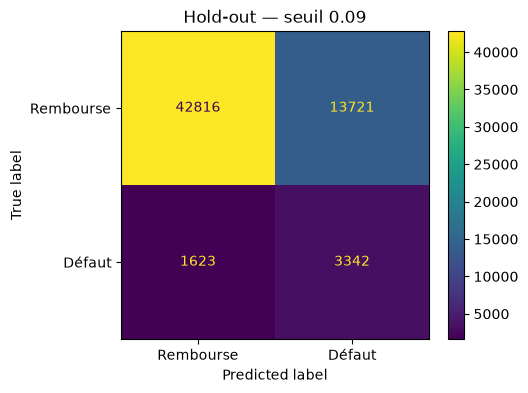

holdout_cout_metier           0.487
holdout_cout_seuil_05         0.778
holdout_cout_tout_accepter    0.807
holdout_auc                   0.787
holdout_accuracy              0.751
holdout_recall_classe1        0.673
holdout_f1_classe1            0.303
dtype: float64

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay

# 1) Entraînement sur tout le train
modele_final.fit(X_train, y_train)

# 2) Prédictions sur les clients jamais vus, avec le seuil fixé sur le train
proba_ho = modele_final.predict_proba(X_holdout)[:, 1]
y_pred_ho = (proba_ho >= SEUIL).astype(int)

metriques_ho = {
    "holdout_cout_metier": cout_metier(y_holdout, y_pred_ho),
    "holdout_cout_seuil_05": cout_metier(y_holdout, (proba_ho >= 0.5).astype(int)),
    "holdout_cout_tout_accepter": cout_metier(y_holdout, np.zeros_like(y_pred_ho)),
    "holdout_auc": roc_auc_score(y_holdout, proba_ho),
    "holdout_accuracy": accuracy_score(y_holdout, y_pred_ho),
    "holdout_recall_classe1": recall_score(y_holdout, y_pred_ho),
    "holdout_f1_classe1": f1_score(y_holdout, y_pred_ho),
}

# 3) Enregistrement MLflow
with mlflow.start_run(run_name="lgbm_final_holdout"):
    mlflow.set_tags({"etape": "evaluation_finale", "modele": "LGBMClassifier"})
    mlflow.log_params({**params_best, "seuil_metier": SEUIL})
    mlflow.log_metrics(metriques_ho)

    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_holdout, y_pred_ho, display_labels=["Rembourse", "Défaut"], ax=ax, values_format="d")
    ax.set_title(f"Hold-out — seuil {SEUIL:.2f}")
    mlflow.log_figure(fig, "matrice_confusion_holdout.png")
    plt.show()

pd.Series(metriques_ho).round(3)

### Évaluation finale
- CV 5 plis sur le train complet (246 005 clients) : coût 0,490, AUC 0,786 ± 0,001, seuil métier 0,09.
- Hold-out (61 502 clients jamais utilisés) : coût 0,487 vs 0,807 si tout accepter (-40 %) ; écart CV/hold-out négligeable → pas de sur-apprentissage.
- 67 % des défauts détectés ; 28 % de demandes refusées, dont 1 sur 5 est un vrai défaut.
- Au seuil 0,5 le coût serait de 0,781 (≈ tout accepter) : l'optimisation du seuil est indispensable.
- Le taux de refus dépend directement de l'hypothèse FN = 10 × FP, à valider avec le métier.
- AUC hold-out 0,787 (CV : 0,786) — sous le seuil d'alerte de 0,82.

### Point de reprise
Le noyau ayant été redémarré, les hyperparamètres optimaux et le seuil métier sont rechargés depuis MLflow
(runs `optuna_lgbm` et `lgbm_optuna_train_complet`) au lieu de relancer l'optimisation (~40 min).
Le modèle final est réentraîné sur le train complet (random_state fixé → résultat reproductible).

In [5]:
import ast
from lightgbm import LGBMClassifier

def dernier_run(nom):
    """Récupère le run MLflow le plus récent portant ce nom."""
    run_id = mlflow.search_runs(filter_string=f"attributes.run_name = '{nom}'",
                                order_by=["start_time DESC"], max_results=1).iloc[0]["run_id"]
    return mlflow.get_run(run_id)

def convertir(valeur):
    """MLflow stocke les paramètres en texte : '800' -> 800, 'None' -> None, 'balanced' reste du texte."""
    try:
        return ast.literal_eval(valeur)
    except (ValueError, SyntaxError):
        return valeur

# Hyperparamètres : meilleur essai Optuna
params_best = {k: convertir(v) for k, v in dernier_run("optuna_lgbm").data.params.items()}
# Seuil : fixé par la validation croisée sur le train complet
SEUIL = dernier_run("lgbm_optuna_train_complet").data.metrics["seuil_optimal"]
print("Paramètres :", params_best)
print("Seuil :", SEUIL)

modele_final = LGBMClassifier(subsample_freq=1, random_state=42, n_jobs=-1, verbose=-1, **params_best)
modele_final.fit(X_train, y_train)

# Contrôle : on doit retrouver les résultats du hold-out
proba_ho = modele_final.predict_proba(X_holdout)[:, 1]
y_pred_ho = (proba_ho >= SEUIL).astype(int)
metriques_ho = {
    "holdout_cout_metier": cout_metier(y_holdout, y_pred_ho),
    "holdout_auc": roc_auc_score(y_holdout, proba_ho),
}
print(metriques_ho)   # attendu : coût ≈ 0.487, AUC ≈ 0.787

Paramètres : {'n_estimators': 800, 'learning_rate': 0.013102498066003072, 'num_leaves': 30, 'min_child_samples': 65, 'colsample_bytree': 0.5892684149904879, 'subsample': 0.7464150178471713, 'reg_alpha': 0.010038432620204023, 'reg_lambda': 1.3968270361333885, 'class_weight': None}
Seuil : 0.09
{'holdout_cout_metier': np.float64(0.4869922929335631), 'holdout_auc': 0.7869858345311604}


In [6]:
import mlflow.pyfunc
from mlflow.models import infer_signature

class ScoringCredit(mlflow.pyfunc.PythonModel):
    """LightGBM + seuil métier : renvoie la probabilité de défaut et la décision."""
    def __init__(self, modele, seuil):
        self.modele = modele
        self.seuil = seuil

    def predict(self, context, model_input, params=None):
        proba = self.modele.predict_proba(model_input)[:, 1]
        return pd.DataFrame({
            "probabilite_defaut": proba,
            "decision": np.where(proba >= self.seuil, "refusé", "accordé"),
        })

scoring = ScoringCredit(modele_final, SEUIL)
exemple = X_holdout.head(5)
scoring.predict(None, exemple)

c:\Users\A491274\Documents\pret-a-depenser\.venv\Lib\site-packages\mlflow\pyfunc\utils\data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


,probabilite_defaut,decision
0,0.061727,accordé
1,0.046290,accordé
2,0.075883,accordé
3,0.039376,accordé
4,0.156157,refusé


In [14]:
from mlflow import MlflowClient

NOM_MODELE = "credit_scoring_lgbm"

# Retrouver le run de l'évaluation finale
run_id = mlflow.search_runs(
    filter_string="attributes.run_name = 'lgbm_final_holdout'",
    order_by=["start_time DESC"], max_results=1).iloc[0]["run_id"]

# La "signature" décrit les colonnes attendues en entrée et le format de sortie
signature = infer_signature(exemple, scoring.predict(None, exemple))

with mlflow.start_run(run_id=run_id):
    info = mlflow.pyfunc.log_model(
        name="modele",
        python_model=scoring,
        signature=signature,
        input_example=exemple,
        registered_model_name=NOM_MODELE,
    )

# Étiquette "champion" sur cette version
client = MlflowClient()
version = info.registered_model_version
client.set_registered_model_alias(NOM_MODELE, "champion", version)
client.update_model_version(NOM_MODELE, version,
    description=f"LightGBM optimisé Optuna, seuil métier {SEUIL:.2f}, coût hold-out "
                f"{metriques_ho['holdout_cout_metier']:.3f}, AUC hold-out {metriques_ho['holdout_auc']:.3f}")
print(f"Modèle '{NOM_MODELE}' version {version} enregistré avec l'alias 'champion'")

c:\Users\A491274\Documents\pret-a-depenser\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/16 10:33:50 WARNING mlflow.pyfunc: Passing a Python object as `python_model` causes it to be serialized using CloudPickle, it requires exercising caution as Python object serialization mechanisms may execute arbit

Modèle 'credit_scoring_lgbm' version 1 enregistré avec l'alias 'champion'


Successfully registered model 'credit_scoring_lgbm'.
Created version '1' of model 'credit_scoring_lgbm'.


In [15]:
modele_charge = mlflow.pyfunc.load_model(f"models:/{NOM_MODELE}@champion")
modele_charge.predict(X_holdout.head(5))

,probabilite_defaut,decision
0,0.061727,accordé
1,0.046290,accordé
2,0.075883,accordé
3,0.039376,accordé
4,0.156157,refusé


### Model Registry
- Le modèle LightGBM est emballé avec son seuil métier (classe pyfunc `ScoringCredit`) : il renvoie la probabilité de défaut ET la décision accordé/refusé, pour ne jamais dépendre du seuil 0,5 par défaut.
- Enregistré sous `credit_scoring_lgbm` (version 1), alias `champion`, avec signature et exemple d'entrée ; rechargement depuis le registry validé (prédictions identiques).
- Limites connues : colonnes entières non nullables dans la signature (sans impact ici, aucune n'a de valeur manquante) ; sérialisation CloudPickle à réserver à des modèles de source fiable.

In [16]:
import json
import requests

clients = X_holdout.head(5)

# Format attendu par MLflow : {"dataframe_split": {"columns": [...], "data": [[...], ...]}}
# to_json transforme les cases vides (NaN) en null, compréhensible par l'API
payload = {"dataframe_split": json.loads(clients.to_json(orient="split", index=False))}

reponse = requests.post("http://127.0.0.1:5001/invocations", json=payload, timeout=30)
print("Statut HTTP :", reponse.status_code)   # 200 = succès
pd.DataFrame(reponse.json()["predictions"])

Statut HTTP : 200


,probabilite_defaut,decision
0,0.061727,accordé
1,0.046290,accordé
2,0.075883,accordé
3,0.039376,accordé
4,0.156157,refusé


### Serving MLflow
- API lancée depuis le registry : `mlflow models serve -m "models:/credit_scoring_lgbm@champion" -p 5001 --env-manager local`.
- Requête POST sur `/invocations` (format `dataframe_split`) avec 5 clients du hold-out : statut 200,
  prédictions identiques au modèle local (probabilité de défaut + décision au seuil métier 0,09).
- L'alias `champion` découple l'API de la version : une nouvelle version se déploie en déplaçant l'alias, sans modifier l'appel.

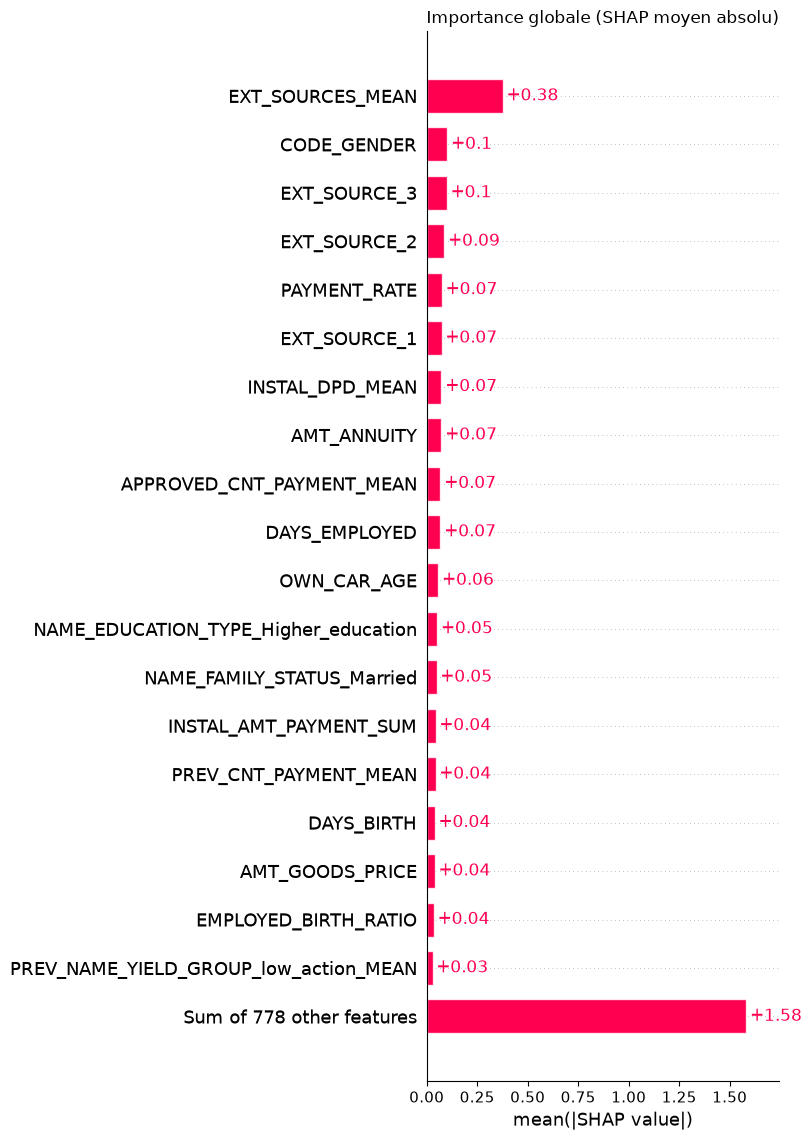

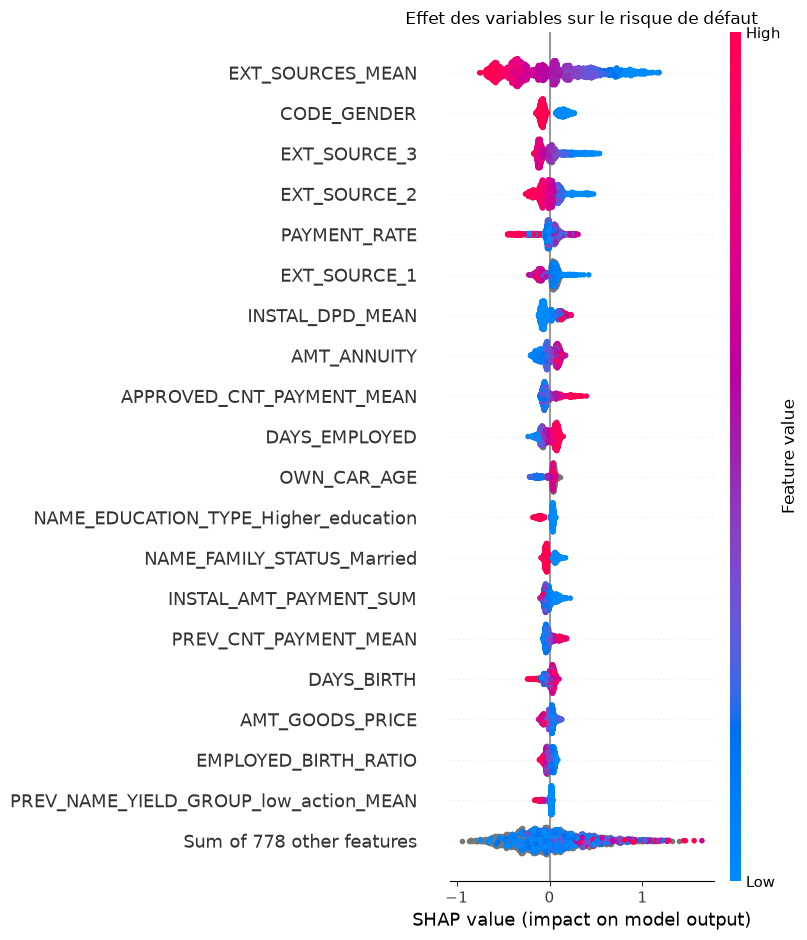

In [17]:
import shap

explainer = shap.TreeExplainer(modele_final)
X_shap = X_holdout.sample(2000, random_state=42)
sv = explainer(X_shap)
if sv.values.ndim == 3:          # certaines versions renvoient les 2 classes : on garde "défaut"
    sv = sv[:, :, 1]

with mlflow.start_run(run_id=run_id):   # on range les graphiques avec le modèle final
    # Vue 1 : importance moyenne (taille de l'effet, sans le sens)
    shap.plots.bar(sv, max_display=20, show=False)
    plt.title("Importance globale (SHAP moyen absolu)")
    plt.tight_layout()
    mlflow.log_figure(plt.gcf(), "shap_global_bar.png")
    plt.show()

    # Vue 2 : beeswarm (taille ET sens de l'effet)
    shap.plots.beeswarm(sv, max_display=20, show=False)
    plt.title("Effet des variables sur le risque de défaut")
    plt.tight_layout()
    mlflow.log_figure(plt.gcf(), "shap_global_beeswarm.png")
    plt.show()

### Interprétabilité globale (SHAP, 2 000 clients du hold-out)
- EXT_SOURCES_MEAN (feature créée) est la variable la plus influente (|SHAP| moyen 0,38, ~4x la suivante).
- PAYMENT_RATE (5e) confirme le lien non linéaire observé malgré une corrélation quasi nulle.
- Les agrégats des tables secondaires contribuent (retards de paiement passés, durée des crédits antérieurs).
- 778 variables cumulent une part importante de faible contribution individuelle → piste de sélection de variables.
- CODE_GENDER est la 2e variable : usage discriminatoire (critère protégé) → retrait à prévoir ; âge et situation familiale à discuter.

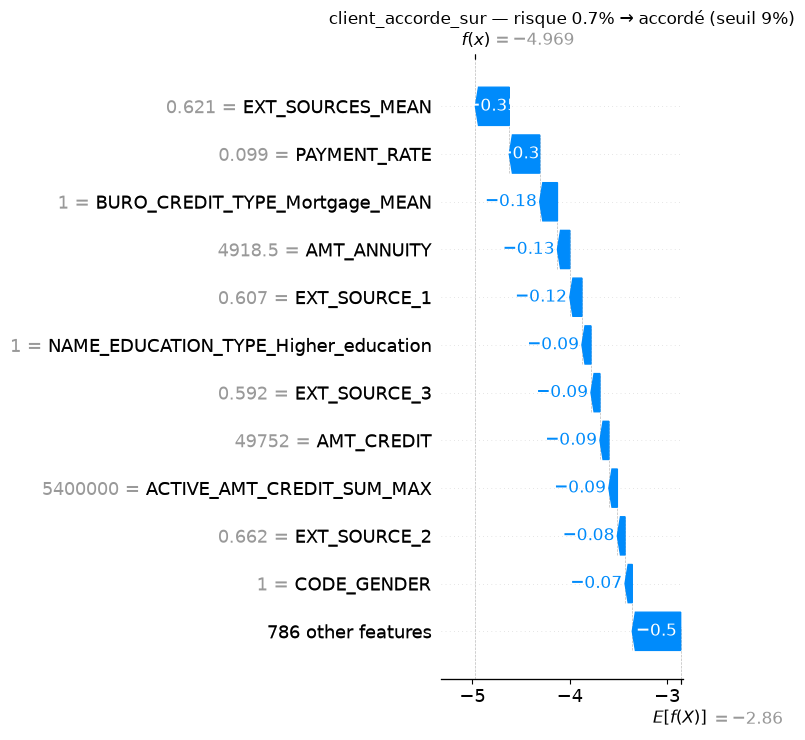

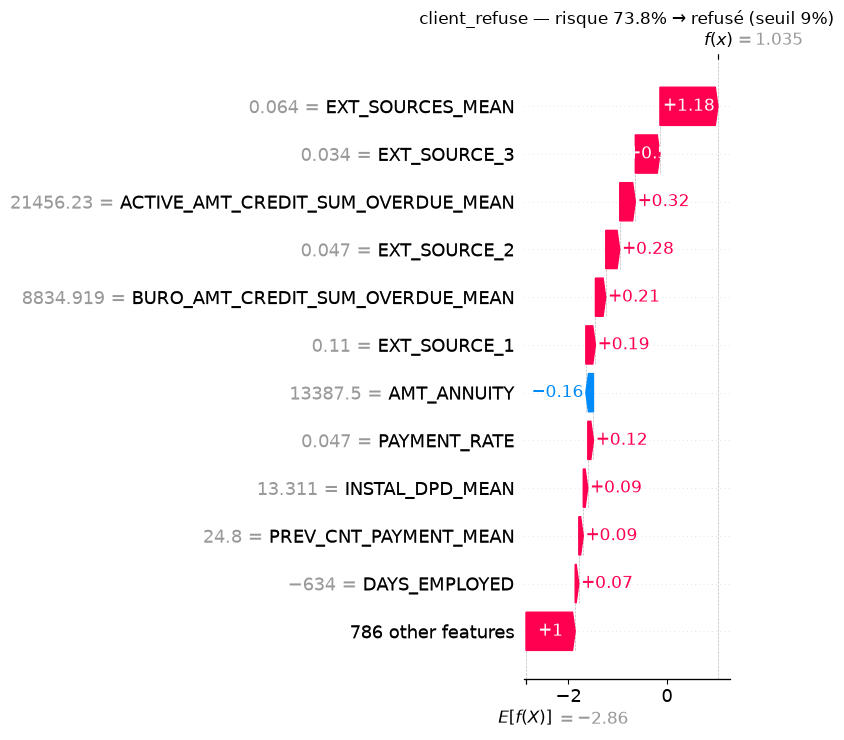

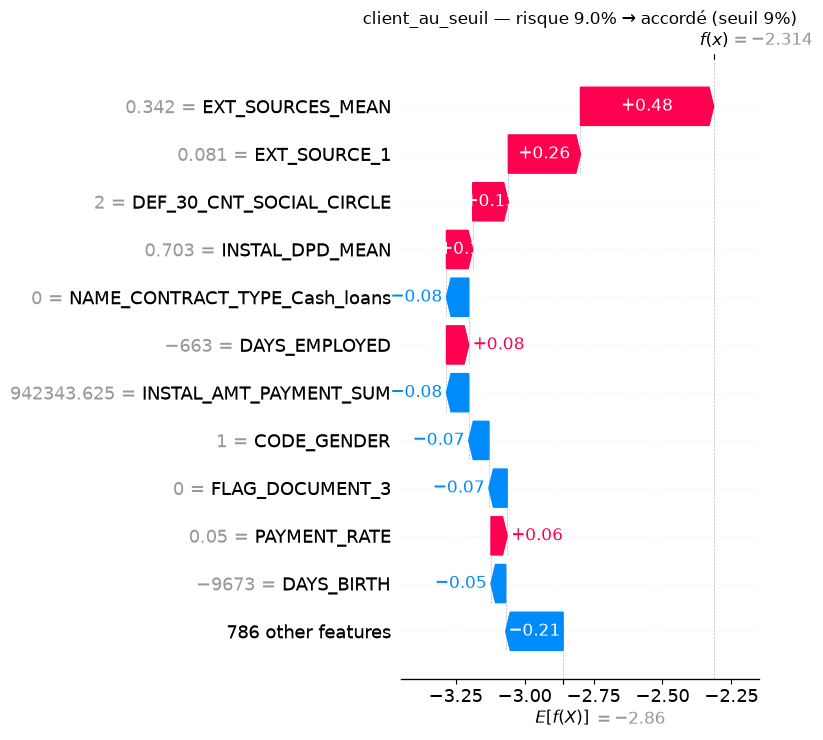

In [18]:
proba_shap = modele_final.predict_proba(X_shap)[:, 1]
clients_types = {
    "client_accorde_sur":  int(np.argmin(proba_shap)),
    "client_refuse":       int(np.argmax(proba_shap)),
    "client_au_seuil":     int(np.argmin(np.abs(proba_shap - SEUIL))),
}

with mlflow.start_run(run_id=run_id):
    for nom, i in clients_types.items():
        decision = "refusé" if proba_shap[i] >= SEUIL else "accordé"
        shap.plots.waterfall(sv[i], max_display=12, show=False)
        plt.title(f"{nom} — risque {proba_shap[i]:.1%} → {decision} (seuil {SEUIL:.0%})")
        plt.tight_layout()
        mlflow.log_figure(plt.gcf(), f"shap_local_{nom}.png")
        plt.show()

### Interprétabilité locale (SHAP waterfall)
- Client accordé (0,7 %) : bons scores externes, remboursement rapide, crédit immobilier existant, études supérieures.
- Client refusé (73,8 %) : scores externes très faibles, impayés en cours sur des crédits actifs ailleurs, retards passés.
  → explication directement communicable par un chargé de clientèle.
- Client au seuil (9,0 %, accordé) : la contribution de CODE_GENDER (-0,07) le fait passer sous le seuil ;
  sans elle, son risque serait ≈ 9,6 % (refusé) → le genre peut faire basculer une décision.
- DEF_30_CNT_SOCIAL_CIRCLE (défauts dans l'entourage) également discutable éthiquement.
- Piste : revue manuelle des dossiers proches du seuil.

In [19]:
pd.read_csv(ROOT / "data" / "raw" / "application_train.csv", usecols=["CODE_GENDER"], nrows=3)

,CODE_GENDER
0,M
1,F
2,M


In [7]:
from mlflow import MlflowClient

NOM_MODELE = "credit_scoring_lgbm"
client = MlflowClient()

In [8]:
COLS_EXCLUES = ["CODE_GENDER"]
X_train_v2 = X_train.drop(columns=COLS_EXCLUES)
X_holdout_v2 = X_holdout.drop(columns=COLS_EXCLUES)

modele_v2 = LGBMClassifier(subsample_freq=1, random_state=42, n_jobs=-1, verbose=-1, **params_best)
res_v2 = evaluer("lgbm_v2_sans_genre_train_complet", modele_v2, X_train_v2, y_train, n_jobs=1,
                 tags={"etape": "validation_train_complet", "version": "v2",
                       "variables_exclues": ",".join(COLS_EXCLUES)})
SEUIL_V2 = float(res_v2["seuil_optimal"])
print(f"Seuil v2 : {SEUIL_V2:.2f}")

lgbm_v2_sans_genre_train_complet coût=0.493 (seuil 0.08) | coût@0.5=0.782 | AUC=0.784±0.001 | 145s
Seuil v2 : 0.08


In [9]:
def metriques_holdout(proba, seuil):
    y_pred = (proba >= seuil).astype(int)
    return {
        "holdout_cout_metier": cout_metier(y_holdout, y_pred),
        "holdout_auc": roc_auc_score(y_holdout, proba),
        "holdout_recall_classe1": recall_score(y_holdout, y_pred),
        "holdout_accuracy": accuracy_score(y_holdout, y_pred),
        "holdout_taux_refus": y_pred.mean(),
    }

# Entraînement et examen sur le hold-out
modele_v2.fit(X_train_v2, y_train)
proba_v2 = modele_v2.predict_proba(X_holdout_v2)[:, 1]
metriques_v2 = metriques_holdout(proba_v2, SEUIL_V2)

# Enregistrement : même nom de modèle → MLflow crée automatiquement la version 2
scoring_v2 = ScoringCredit(modele_v2, SEUIL_V2)
exemple_v2 = X_holdout_v2.head(5)
with mlflow.start_run(run_name="lgbm_v2_holdout"):
    mlflow.set_tags({"etape": "evaluation_finale", "version": "v2",
                     "variables_exclues": ",".join(COLS_EXCLUES)})
    mlflow.log_params({**params_best, "seuil_metier": SEUIL_V2})
    mlflow.log_metrics(metriques_v2)
    info_v2 = mlflow.pyfunc.log_model(
        name="modele",
        python_model=scoring_v2,
        signature=infer_signature(exemple_v2, scoring_v2.predict(None, exemple_v2)),
        input_example=exemple_v2,
        registered_model_name=NOM_MODELE,
    )

version_v2 = info_v2.registered_model_version
client.update_model_version(NOM_MODELE, version_v2,
    description=f"v2 : LightGBM sans CODE_GENDER (non-discrimination), seuil {SEUIL_V2:.2f}, "
                f"coût hold-out {metriques_v2['holdout_cout_metier']:.3f}, AUC {metriques_v2['holdout_auc']:.3f}")

# Comparaison v1 / v2 sur le même hold-out
pd.DataFrame({"v1_avec_genre": metriques_holdout(proba_ho, SEUIL),
              "v2_sans_genre": metriques_v2}).round(4)

c:\Users\A491274\Documents\pret-a-depenser\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/19 15:10:54 WARNING mlflow.pyfunc: Passing a Python object as `python_model` causes it to be serialized using CloudPickle, it requires exercising caution as Python object serialization mechanisms may execute arbit

,v1_avec_genre,v2_sans_genre
holdout_cout_metier,0.4870,0.4913
holdout_auc,0.7870,0.7855
holdout_recall_classe1,0.6731,0.7094
holdout_accuracy,0.7505,0.7199
holdout_taux_refus,0.2774,0.3139


### Version 2 : retrait de CODE_GENDER
- Vérification : codage homme = 0, femme = 1 → la v1 attribuait un risque plus élevé aux hommes à dossier égal.
- Même protocole que la v1 (hyperparamètres Optuna, seuil fixé en CV sur le train complet, évaluation hold-out).
- Hold-out : coût 0,491 vs 0,487 (+0,9 %), AUC 0,786 vs 0,787 → impact négligeable.
- Seuil 0,08 vs 0,09 : courbe coût/seuil plate près de l'optimum ; taux de refus 31 % vs 28 %.
  Le choix du seuil dans cette zone est un levier métier (coût quasi identique, taux de refus différent).
- Décision : v2 promue `champion` (critère protégé exclu pour un surcoût < 1 %).

In [10]:
client.set_registered_model_alias(NOM_MODELE, "champion", version_v2)

client.set_model_version_tag(NOM_MODELE, "1", "statut", "retiré")
client.set_model_version_tag(NOM_MODELE, "1", "motif", "utilise CODE_GENDER (critère discriminatoire)")
client.set_model_version_tag(NOM_MODELE, version_v2, "statut", "production")

modele_champion = mlflow.pyfunc.load_model(f"models:/{NOM_MODELE}@champion")
print(f"'champion' pointe maintenant sur la version {version_v2}")
modele_champion.predict(X_holdout_v2.head(5))

'champion' pointe maintenant sur la version 2


,probabilite_defaut,decision
0,0.049013,accordé
1,0.035987,accordé
2,0.079530,accordé
3,0.040800,accordé
4,0.130639,refusé


In [11]:
import json, requests

clients = X_holdout_v2.head(5)    # 796 colonnes : la v2 n'attend plus CODE_GENDER
payload = {"dataframe_split": json.loads(clients.to_json(orient="split", index=False))}
reponse = requests.post("http://127.0.0.1:5001/invocations", json=payload, timeout=30)
print("Statut HTTP :", reponse.status_code)
pd.DataFrame(reponse.json()["predictions"])

Statut HTTP : 200


,probabilite_defaut,decision
0,0.049013,accordé
1,0.035987,accordé
2,0.079530,accordé
3,0.040800,accordé
4,0.130639,refusé


### Déploiement de la v2
- Alias `champion` déplacé de la version 1 à la version 2 ; v1 conservée avec les tags statut = retiré et motif.
- Le serveur relancé avec la même commande (`models:/credit_scoring_lgbm@champion`) sert automatiquement la v2 :
  prédictions de l'API identiques au modèle chargé depuis le registry.

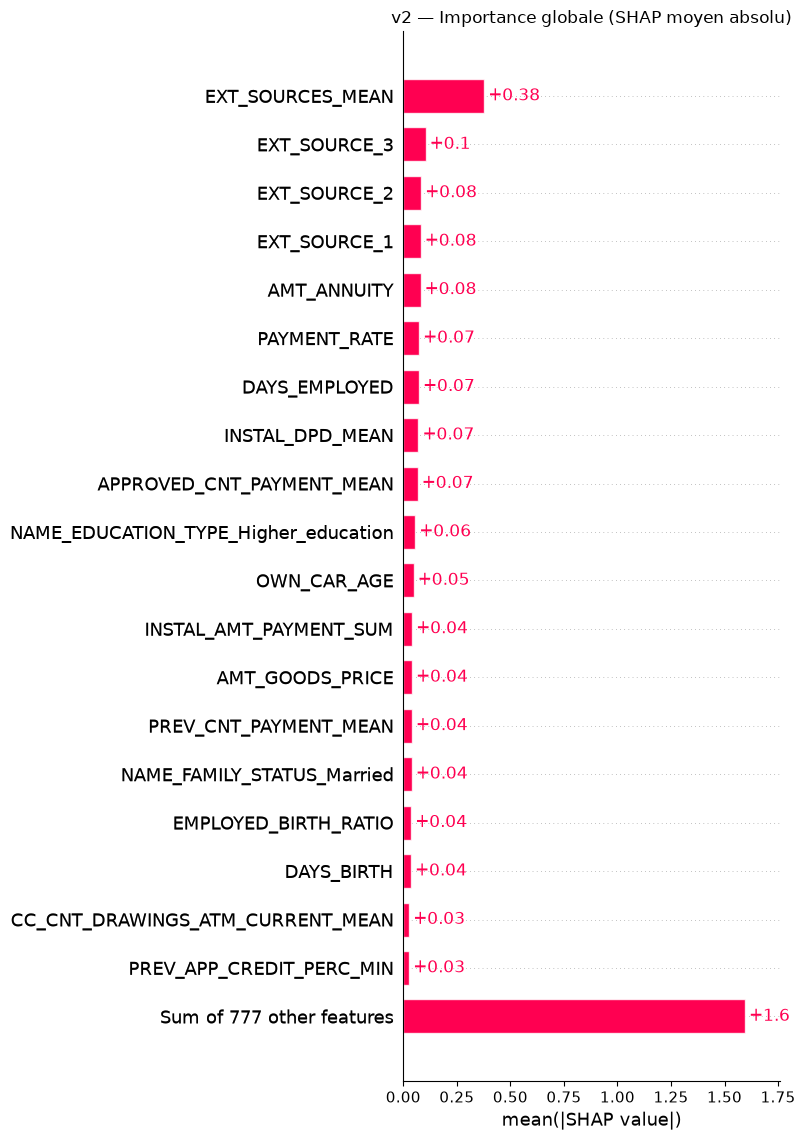

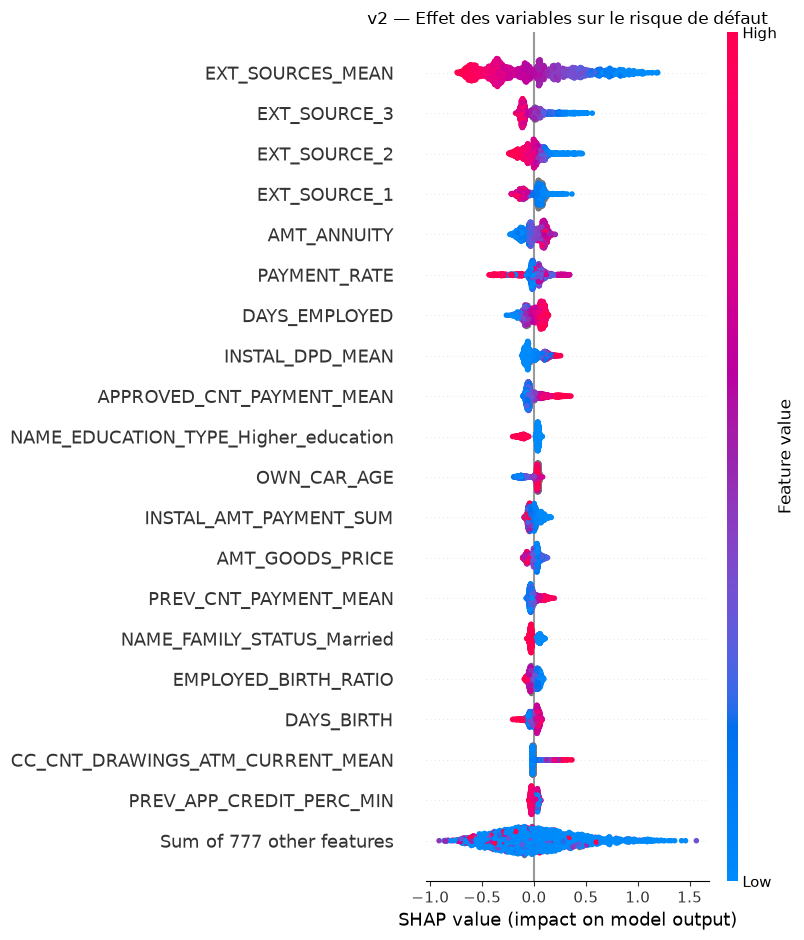

EXT_SOURCES_MEAN                        0.378
EXT_SOURCE_3                            0.104
EXT_SOURCE_2                            0.083
EXT_SOURCE_1                            0.081
AMT_ANNUITY                             0.081
PAYMENT_RATE                            0.074
DAYS_EMPLOYED                           0.073
INSTAL_DPD_MEAN                         0.071
APPROVED_CNT_PAYMENT_MEAN               0.067
NAME_EDUCATION_TYPE_Higher_education    0.056
dtype: float64

In [12]:
import shap

run_id_v2 = mlflow.search_runs(filter_string="attributes.run_name = 'lgbm_v2_holdout'",
                               order_by=["start_time DESC"], max_results=1).iloc[0]["run_id"]

explainer_v2 = shap.TreeExplainer(modele_v2)
X_shap_v2 = X_holdout_v2.sample(2000, random_state=42)
sv_v2 = explainer_v2(X_shap_v2)
if sv_v2.values.ndim == 3:
    sv_v2 = sv_v2[:, :, 1]

with mlflow.start_run(run_id=run_id_v2):
    shap.plots.bar(sv_v2, max_display=20, show=False)
    plt.title("v2 — Importance globale (SHAP moyen absolu)")
    plt.tight_layout()
    mlflow.log_figure(plt.gcf(), "shap_global_bar.png")
    plt.show()

    shap.plots.beeswarm(sv_v2, max_display=20, show=False)
    plt.title("v2 — Effet des variables sur le risque de défaut")
    plt.tight_layout()
    mlflow.log_figure(plt.gcf(), "shap_global_beeswarm.png")
    plt.show()

# Top 10 en texte, plus simple à comparer avec la v1
pd.Series(np.abs(sv_v2.values).mean(axis=0), index=X_shap_v2.columns) \
  .sort_values(ascending=False).head(10).round(3)

### Interprétabilité globale v2
- Classement quasi identique à la v1 sans le genre : EXT_SOURCES_MEAN (0,378), puis EXT_SOURCE_3/2/1, mensualité, PAYMENT_RATE, ancienneté d'emploi, retards passés.
- Nouvelle variable dans le top 20 : retraits d'espèces par carte de crédit (signal de besoin de trésorerie).
- Limite : le retrait de CODE_GENDER n'exclut pas une discrimination indirecte via des variables corrélées (proxies) → contrôle par comparaison des taux de refus par sexe.

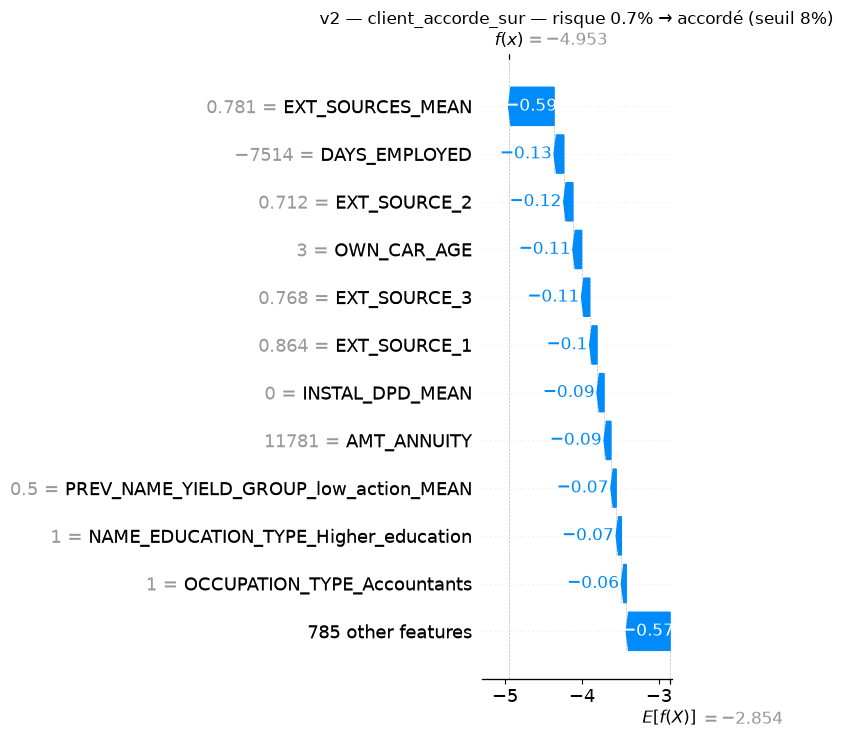

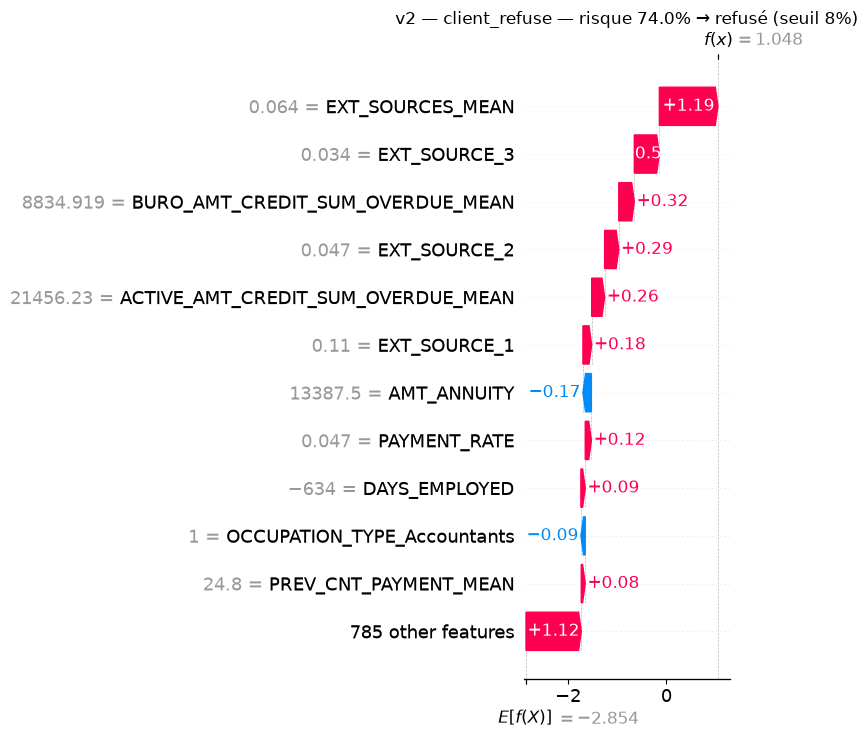

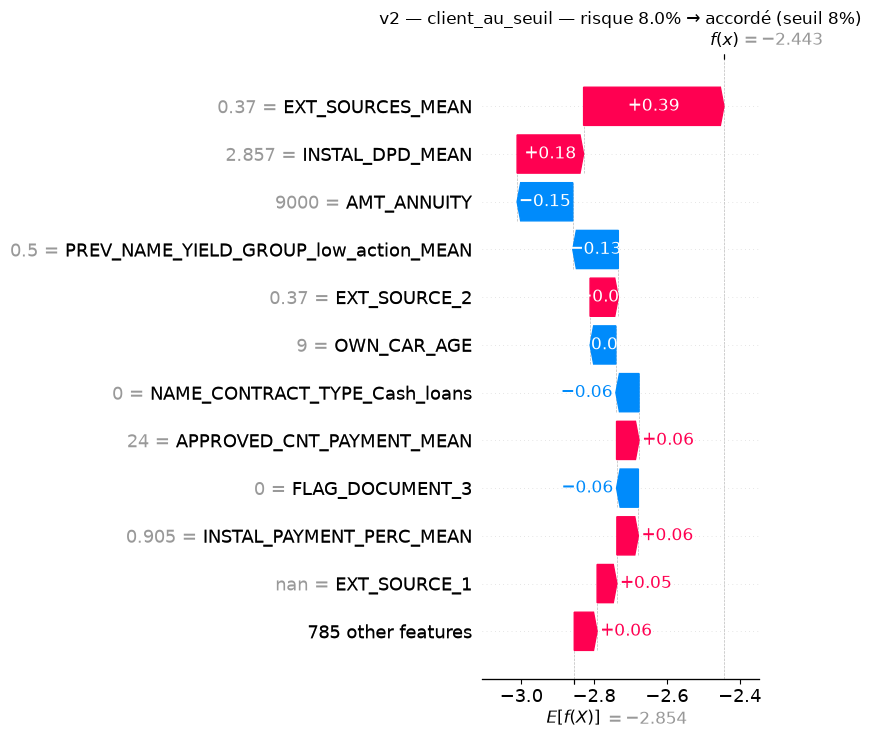

In [13]:
proba_shap_v2 = modele_v2.predict_proba(X_shap_v2)[:, 1]
clients_types_v2 = {
    "client_accorde_sur": int(np.argmin(proba_shap_v2)),
    "client_refuse":      int(np.argmax(proba_shap_v2)),
    "client_au_seuil":    int(np.argmin(np.abs(proba_shap_v2 - SEUIL_V2))),
}

with mlflow.start_run(run_id=run_id_v2):
    for nom, i in clients_types_v2.items():
        decision = "refusé" if proba_shap_v2[i] >= SEUIL_V2 else "accordé"
        shap.plots.waterfall(sv_v2[i], max_display=12, show=False)
        plt.title(f"v2 — {nom} — risque {proba_shap_v2[i]:.1%} → {decision} (seuil {SEUIL_V2:.0%})")
        plt.tight_layout()
        mlflow.log_figure(plt.gcf(), f"shap_local_{nom}.png")
        plt.show()

### Interprétabilité locale v2
- Client refusé (74 %) : identique à la v1 (scores externes très faibles, impayés en cours) → les décisions nettes ne dépendaient pas du genre.
- Client accordé (0,7 %) : scores externes élevés, ~20 ans d'ancienneté, aucun retard passé.
- Client au seuil (8,0 %) : retards et paiements partiels passés ; EXT_SOURCE_1 manquant augmente le risque,
  ce qui confirme le caractère informatif des valeurs manquantes (notebook 01) → candidat à une revue manuelle.

In [14]:
genre = X_holdout["CODE_GENDER"].map({0: "Homme", 1: "Femme"})

equite = pd.DataFrame({
    "nb_clients":       genre.value_counts(),
    "taux_defaut_reel": y_holdout.groupby(genre).mean(),
    "taux_refus_v1":    pd.Series((proba_ho >= SEUIL).astype(int), index=X_holdout.index).groupby(genre).mean(),
    "taux_refus_v2":    pd.Series((proba_v2 >= SEUIL_V2).astype(int), index=X_holdout.index).groupby(genre).mean(),
})
equite.round(3)

,nb_clients,taux_defaut_reel,taux_refus_v1,taux_refus_v2
CODE_GENDER,,,,
Femme,40544,0.070,0.23,0.28
Homme,20958,0.102,0.37,0.38


### Contrôle d'équité (hold-out, CODE_GENDER conservé uniquement pour l'audit)
- Défaut réel : femmes 7,0 %, hommes 10,2 % (rapport 1,46).
- v1 : refus 23 % / 37 % (rapport 1,61) → la v1 amplifiait l'écart de risque réel.
- v2 : refus 28 % / 38 % (rapport 1,36) → écart réduit de 14 à 10 points, inférieur à l'écart de risque réel.
- L'écart résiduel provient d'autres variables (revenus, emploi, historique) et possiblement de proxies.
- Limite : le seuil a aussi changé (0,09 → 0,08), ce qui augmente les refus pour tous.
- Piste : suivre en production les taux de refus et de détection par groupe (audit d'équité régulier).

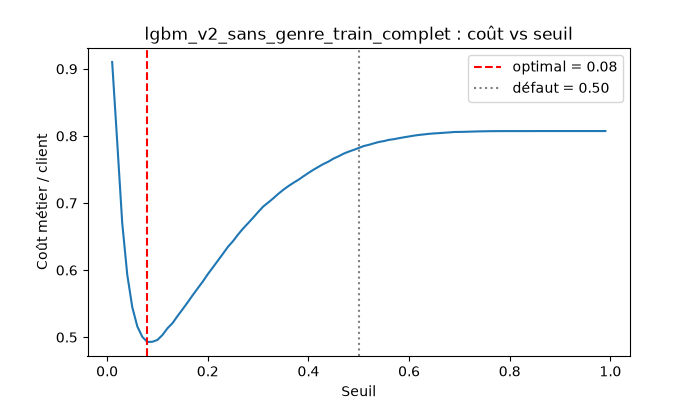

In [15]:
run_cv_v2 = mlflow.search_runs(
    filter_string="attributes.run_name = 'lgbm_v2_sans_genre_train_complet'",
    order_by=["start_time DESC"], max_results=1).iloc[0]["run_id"]

mlflow.artifacts.load_image(f"runs:/{run_cv_v2}/cout_vs_seuil.png")